MALL CUSTOMERS DATASET
--------------------------------------------------
Dataset shape: (200, 5)

First five records:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']
Number of customer records: 200


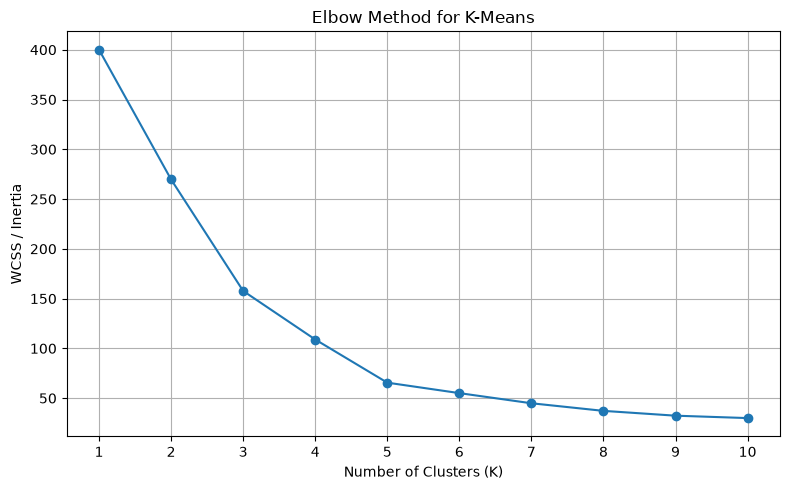


SILHOUETTE SCORES FOR K-MEANS
K = 2: Silhouette Score = 0.3213
K = 3: Silhouette Score = 0.4666
K = 4: Silhouette Score = 0.4939
K = 5: Silhouette Score = 0.5547
K = 6: Silhouette Score = 0.5399
K = 7: Silhouette Score = 0.5281
K = 8: Silhouette Score = 0.4552
K = 9: Silhouette Score = 0.4571
K = 10: Silhouette Score = 0.4432

CLUSTERING PERFORMANCE COMPARISON
              Algorithm  Number of Clusters  Silhouette Score  Davies-Bouldin Index
                K-Means                   5            0.5547                0.5722
Hierarchical Clustering                   5            0.5538                0.5779


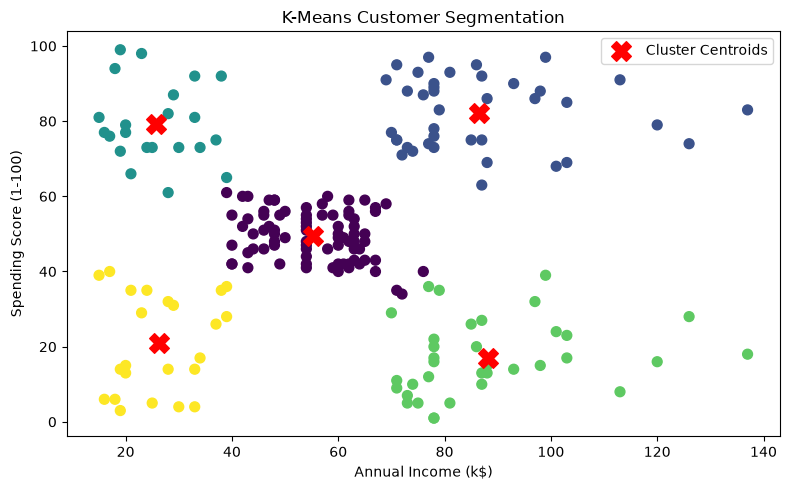

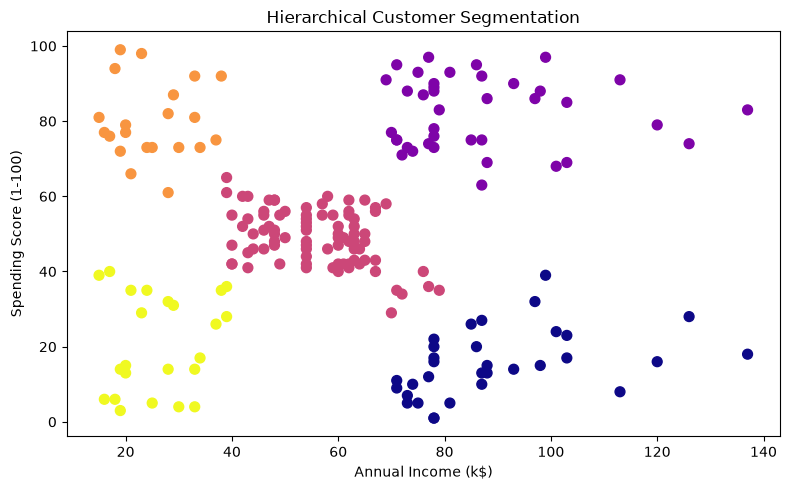

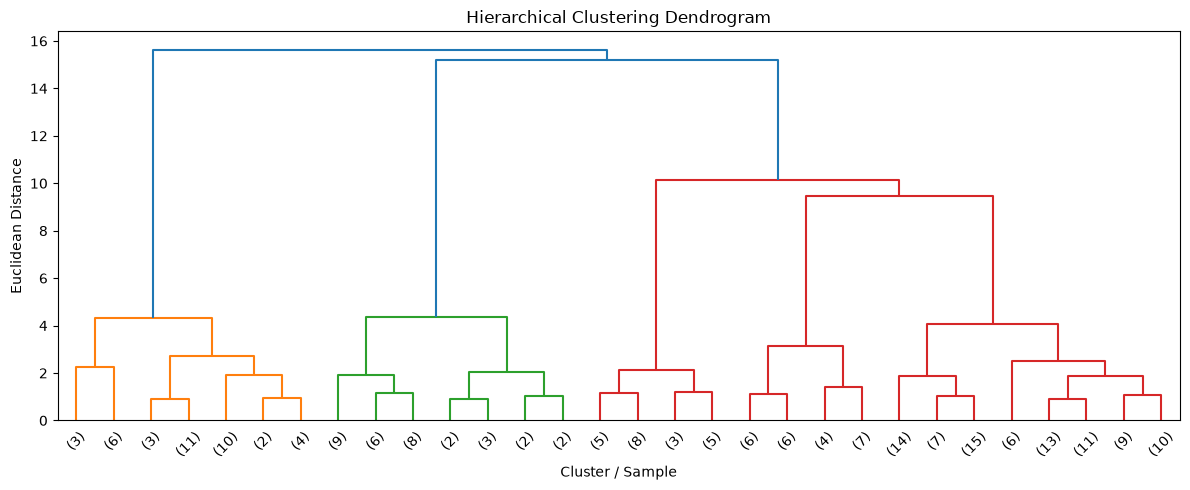


Files saved successfully:
- mall_customer_cluster_results.csv
- clustering_performance_results.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load the dataset
df = pd.read_csv("Mall_Customers.csv")

print("MALL CUSTOMERS DATASET")
print("-" * 50)
print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

# 2. Select clustering features
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

# 3. Handle missing values
X = X.fillna(X.median())

# 4. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nSelected features:", features)
print("Number of customer records:", len(X))

# 5. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Compare silhouette scores for different K values
print("\nSILHOUETTE SCORES FOR K-MEANS")

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    print(f"K = {k}: Silhouette Score = {score:.4f}")

# 7. Fit K-Means with five clusters
# Five clusters are a common starting point for this dataset.
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# 8. Fit Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

# 9. Evaluate both algorithms
results = []

for name, labels in [
    ("K-Means", kmeans_labels),
    ("Hierarchical Clustering", hierarchical_labels)
]:
    silhouette = silhouette_score(X_scaled, labels)
    db_index = davies_bouldin_score(X_scaled, labels)

    results.append({
        "Algorithm": name,
        "Number of Clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index
    })

results_df = pd.DataFrame(results)

print("\nCLUSTERING PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))

# 10. Visualize K-Means clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Cluster Centroids"
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()
plt.show()

# 11. Visualize Hierarchical Clustering
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=hierarchical_labels,
    cmap="plasma",
    s=50
)

plt.title("Hierarchical Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

# 12. Generate a dendrogram
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster / Sample")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

# 13. Save cluster assignments
output_df = df.copy()
output_df["KMeans_Cluster"] = kmeans_labels
output_df["Hierarchical_Cluster"] = hierarchical_labels

output_df.to_csv("mall_customer_cluster_results.csv", index=False)

results_df.to_csv("clustering_performance_results.csv", index=False)

print("\nFiles saved successfully:")
print("- mall_customer_cluster_results.csv")
print("- clustering_performance_results.csv")